# __Project: Mandarin ASR with wav2vec 2.0 and CTC__

- This project follows the general workflow of the Hugging Face tutorial [Fine-Tuning XLS-R for Multilingual ASR with 🤗 Transformers](https://huggingface.co/blog/fine-tune-xlsr-wav2vec2). 

- The original tutorial has been adapted to the current Hugging Face Transformers API and to Mandarin speech recognition using the AISHELL-3 corpus.

- The goal of the project is to fine-tune a pretrained XLS-R model for Mandarin automatic speech recognition (ASR) using Connectionist Temporal Classification (CTC). Two output representations are investigated:

1. Chinese characters (Hanzi)
2. Tone-marked Pinyin syllables

- This notebook covers the forth part of the project, including the evaluation of the model's performance on the test set, also some further test on the model's bias.

- _AI-assisted development was used for code explanation, debugging, and API migration. Python version 3.13.14, Transformers version 5.12.1_

In [15]:
import json
from pathlib import Path, PureWindowsPath

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from jiwer import wer
from matplotlib.ticker import PercentFormatter


In [24]:
PROJECT_ROOT = Path.cwd()
if (PROJECT_ROOT / "semester-project-chinese-ASR").is_dir():
    PROJECT_ROOT = PROJECT_ROOT / "semester-project-chinese-ASR"

TASKS = {
    "hanzi": ("Hanzi", "cer", "hanzi_character"),
    "pinyin": ("Pinyin syllable", "wer", "pinyin syllable with tone"),
    "letter": ("Pinyin letter", "cer", "pinyin in separate letter and tone"),
}

run_dirs = {
    task: PROJECT_ROOT / "model_outputs" / task / "finetune_v2"
    for task in TASKS
}

print(run_dirs)


{'hanzi': WindowsPath('d:/shuangpingpho/semester-project-chinese-ASR/model_outputs/hanzi/finetune_v2'), 'pinyin': WindowsPath('d:/shuangpingpho/semester-project-chinese-ASR/model_outputs/pinyin/finetune_v2'), 'letter': WindowsPath('d:/shuangpingpho/semester-project-chinese-ASR/model_outputs/letter/finetune_v2')}


In [25]:
summary_rows = []

for task, (name, metric_name, unit) in TASKS.items():
    metrics_path = run_dirs[task] / "test_metrics.json"

    print(metrics_path)
    if not metrics_path.is_file():
        print(f"Skip {name}：cannot find {metrics_path}")
        continue

    summary = json.loads(metrics_path.read_text(encoding="utf-8"))
    checkpoint = summary.get("checkpoint")

    summary_rows.append({
        "Model": name,
        "Checkpoint": PureWindowsPath(checkpoint).name if checkpoint else "—",
        "Data Size": summary["num_examples"],
        "Metrics": metric_name.upper(),
        "Unit": unit,
        "Error_Rate": f"{summary['score']:.2%}",
    })

if summary_rows:
    display(pd.DataFrame(summary_rows))

d:\shuangpingpho\semester-project-chinese-ASR\model_outputs\hanzi\finetune_v2\test_metrics.json
d:\shuangpingpho\semester-project-chinese-ASR\model_outputs\pinyin\finetune_v2\test_metrics.json
Skip Pinyin syllable：cannot find d:\shuangpingpho\semester-project-chinese-ASR\model_outputs\pinyin\finetune_v2\test_metrics.json
d:\shuangpingpho\semester-project-chinese-ASR\model_outputs\letter\finetune_v2\test_metrics.json
Skip Pinyin letter：cannot find d:\shuangpingpho\semester-project-chinese-ASR\model_outputs\letter\finetune_v2\test_metrics.json


,Model,Checkpoint,Data Size,Metrics,Unit,Error_Rate
0,Hanzi,checkpoint-7119,24773,CER,hanzi_character,27.86%


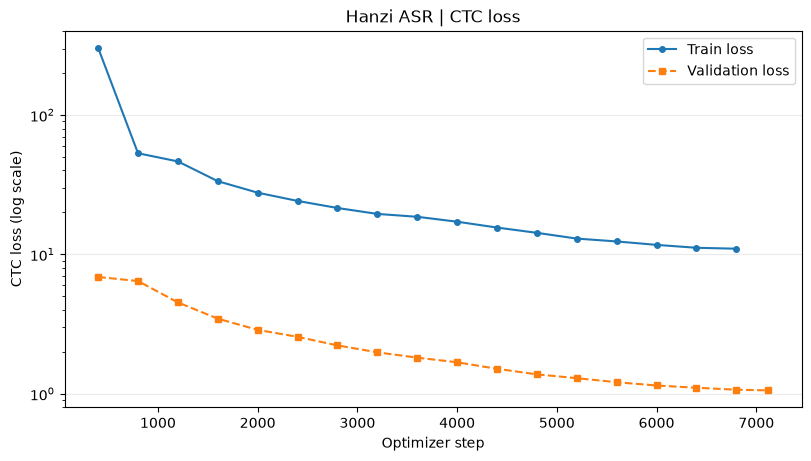

Skip Pinyin syllable：cannot find d:\shuangpingpho\semester-project-chinese-ASR\model_outputs\pinyin\finetune_v2\checkpoint-7119\trainer_state.json
Skip Pinyin letter：cannot find d:\shuangpingpho\semester-project-chinese-ASR\model_outputs\letter\finetune_v2\checkpoint-7119\trainer_state.json


In [29]:
for task, (name, metric_name, unit) in TASKS.items():
    state_path = run_dirs[task] / "checkpoint-7119" /"trainer_state.json"

    if not state_path.is_file():
            print(f"Skip {name}：cannot find {state_path}")
            continue
    
    history = json.loads(state_path.read_text(encoding="utf-8"))["log_history"]

    train_points = sorted(
        (row["step"], row["loss"])
        for row in history
        if "step" in row and "loss" in row
    )
    val_points = sorted(
        (row["step"], row["eval_loss"])
        for row in history
        if "step" in row and "eval_loss" in row
    )

    train_steps, train_losses = zip(*train_points)
    val_steps, val_losses = zip(*val_points)

    fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
    ax.plot(train_steps, train_losses, marker="o", markersize=4, label="Train loss")
    ax.plot(
        val_steps, val_losses,
        marker="s", markersize=4, linestyle="--", label="Validation loss",
    )

    ax.set_yscale("log")
    ax.set(
        title="Hanzi ASR | CTC loss",
        xlabel="Optimizer step",
        ylabel="CTC loss (log scale)",
    )
    ax.grid(axis="y", alpha=0.25)
    ax.legend()
    plt.show()